# 04 – Embeddings, UMAP och HDBSCAN

Den tredje metoden skiljer sig från K-means och LDA på två sätt:

1. **Embeddings i stället för ordräkning.** TF-IDF och Bag of Words ser bara *vilka ord* som används. En embedding-modell är ett förtränat neuralt nätverk som omvandlar varje text till 384 tal som beskriver textens *betydelse*. Texter med liknande innehåll hamnar nära varandra även om de använder olika ord, t.ex. "someone stole my card" och "unauthorized purchases on my account".
2. **HDBSCAN i stället för K-means.** HDBSCAN behöver inte veta antalet kluster i förväg, utan hittar själv områden där texterna ligger tätt. Texter som inte passar in någonstans markeras som **brus** i stället för att tvingas in i ett kluster.

Mellan stegen används **UMAP** för att minska antalet dimensioner från 384 till ett fåtal, eftersom HDBSCAN fungerar dåligt i många dimensioner.

Detta experiment går utöver kursens innehåll.

**Upplägg:**
1. Urval och embeddings
2. UMAP
3. HDBSCAN
4. Tolkning av klustren
5. Jämförelse med K-means och LDA
6. Sammanfattande jämförelse av de tre metoderna

Alla slumpmässiga steg använder `random_state=42`.

## 1. Urval och embeddings

**Stickprov på 20 000 klagomål:** att beräkna embeddings för alla 101 373 klagomål tar för lång tid på en vanlig dator. Ett slumpmässigt urval på 20 000 räcker för att hitta de vanliga ärendetyperna och jämföra med de andra metoderna.

**Lättare textrensning:** embedding-modellen är tränad på vanlig text och förstår meningar, skiljetecken och vanliga ord. Därför tas bara CFPB:s maskering ("XXXX") och belopp bort. Stoppord behålls, eftersom de bär betydelse i en mening ("not", "never").

**Borttagning av företagsnamn:** företagsnamn ersätts med "the company", så att meningarna förblir naturliga för modellen. Varför detta behövdes beskrivs i avsnitt 3.

**Modell:** `all-MiniLM-L6-v2`, en liten och snabb modell som är vanlig för klustring av text. Den läser de första ca 200 orden i varje text. Längre texter kortas av, vilket är en begränsning.

Embeddings sparas till fil så att de bara behöver beräknas en gång.

In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/complaints_lda.parquet")

urval = df.sample(20_000, random_state=42).reset_index(drop=True)

foretag_regex = re.compile(
    r"\b(wells fargo|bank of america|boa|jpmorgan|chase|capital ?one|capitol one|"
    r"paypal|venmo|zelle|cash ?app|cashapp|affirm|mohela|navient|nelnet|citibank|citi|"
    r"synchrony|american express|amex|barclays?|coinbase|santander|ally|truist|pnc|"
    r"discover|navy federal( credit union)?|nfcu|chime|huntington|usaa|marcus|"
    r"goldman sachs|lowes|wise|western union|td bank|fifth third)\b",
    flags=re.IGNORECASE,
)

def latt_rensning(t):
    t = re.sub(r"\bX{2,}\b", " ", t)        # maskering
    t = re.sub(r"\{\$[\d,.]+\}", " ", t)    # belopp
    t = foretag_regex.sub("the company", t) # företagsnamn
    t = re.sub(r"\s+", " ", t).strip()
    return t

urval["text_embed"] = urval["Consumer complaint narrative"].apply(latt_rensning)

print("Antal klagomål i urvalet:", len(urval))
print("\nProdukter i urvalet (andel):")
print(urval["Product"].value_counts(normalize=True).round(3))
print("\nExempel:\n", urval["text_embed"].iloc[0][:300])

Antal klagomål i urvalet: 20000

Produkter i urvalet (andel):
Product
Debt collection                                       0.257
Credit card or prepaid card                           0.224
Checking or savings account                           0.221
Mortgage                                              0.107
Money transfer, virtual currency, or money service    0.069
Vehicle loan or lease                                 0.059
Payday loan, title loan, or personal loan             0.033
Student loan                                          0.028
Name: proportion, dtype: float64

Exempel:
 There were Fraudulent transactions on an the company Checking Account I had last year. My account was unknowingly compromised from someone I DO NOT know which a check for $ as result I closed my Account by calling the company Customer Service to stop further activity! NOW Im currently in debt of tha


In [3]:
from pathlib import Path
from sentence_transformers import SentenceTransformer

emb_fil = Path("../data/embeddings_20k_utan_foretag.npy")

if emb_fil.exists():
    embeddings = np.load(emb_fil)
    print("Embeddings inlästa från fil")
else:
    modell = SentenceTransformer("all-MiniLM-L6-v2")
    embeddings = modell.encode(
        urval["text_embed"].tolist(),
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    np.save(emb_fil, embeddings)
    print("Embeddings beräknade och sparade")

print("Storlek:", embeddings.shape)
urval.to_parquet("../data/urval_20k.parquet")

c:\Users\frida\Documents\Frida\customer-complaint-clustering\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Embeddings inlästa från fil
Storlek: (20000, 384)


Urvalets produktfördelning motsvarar hela datasetet (t.ex. inkasso 26 %, kort 22 %, bankkonton 22 %), så urvalet bedöms som representativt. Beräkningen av embeddings tog ca 8 minuter på en vanlig bärbar dator.

## 2. UMAP

**UMAP** minskar antalet dimensioner från 384 till färre, och försöker samtidigt bevara vilka texter som ligger nära varandra. Två versioner skapas:

- **10 dimensioner** används för klustringen. Det är tillräckligt få för att HDBSCAN ska fungera, men behåller mer information än 2 dimensioner.
- **2 dimensioner** används enbart för att kunna rita en karta över texterna.

`metric="cosine"` används eftersom det är vinkeln mellan embeddings, inte deras längd, som beskriver hur lika två texter är.

c:\Users\frida\Documents\Frida\customer-complaint-clustering\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\frida\Documents\Frida\customer-complaint-clustering\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


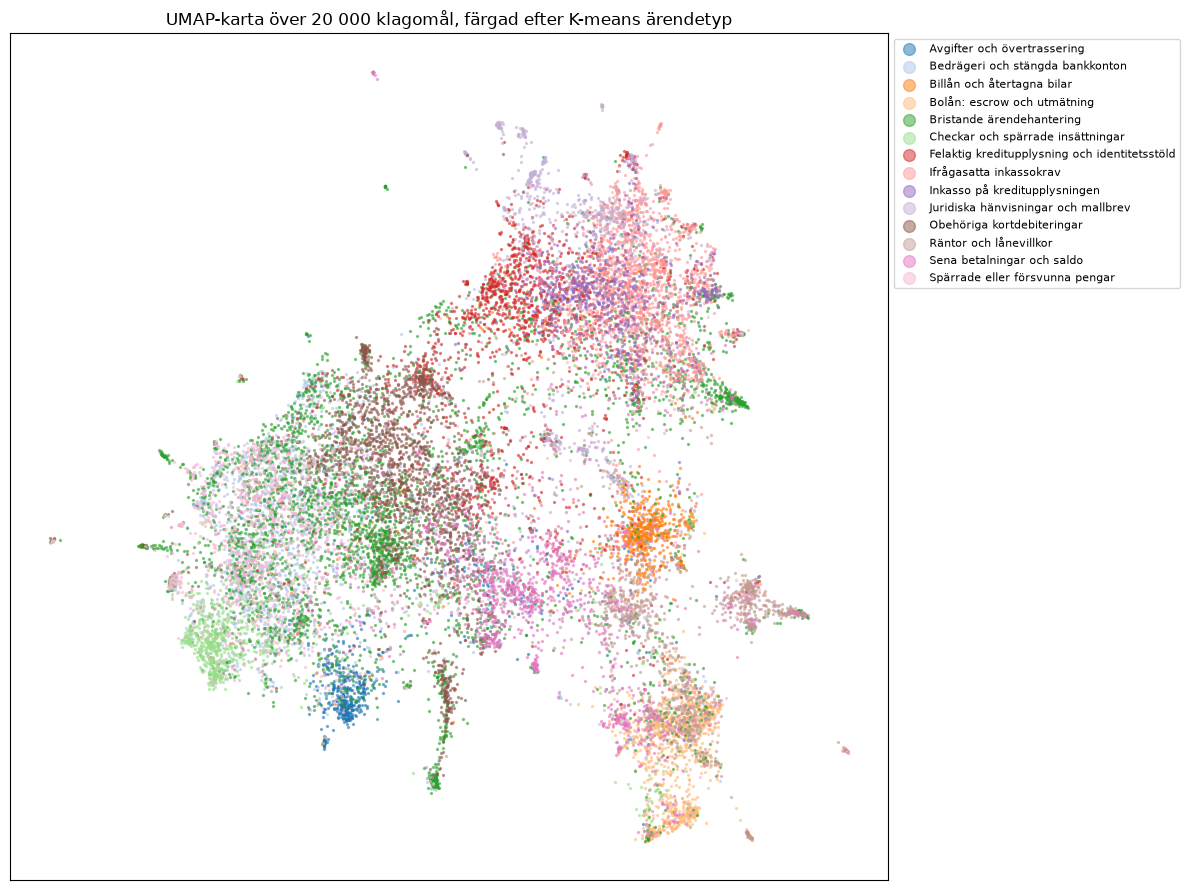

In [4]:
import umap

red10 = umap.UMAP(n_neighbors=15, n_components=10, min_dist=0.0,
                  metric="cosine", random_state=42)
X_umap = red10.fit_transform(embeddings)

red2 = umap.UMAP(n_neighbors=15, n_components=2, min_dist=0.1,
                 metric="cosine", random_state=42)
X_2d = red2.fit_transform(embeddings)

# Karta färgad efter K-means ärendetyp, för att se om embeddings separerar ärendetyperna
farger = plt.cm.tab20.colors

fig, ax = plt.subplots(figsize=(12, 9))
for i, (namn, grupp) in enumerate(urval.groupby("arendetyp")):
    idx = grupp.index
    ax.scatter(X_2d[idx, 0], X_2d[idx, 1], s=2, alpha=0.5,
               color=farger[i % 20], label=namn)
ax.set_title("UMAP-karta över 20 000 klagomål, färgad efter K-means ärendetyp")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(markerscale=6, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

**Resultat – UMAP-kartan:**

- Embeddings separerar flera ärendetyper i tydliga regioner: inkasso och kreditupplysning (uppe till höger), billån (mitten till höger), bolån (nere till höger) samt checkar och avgifter (nere till vänster). Det liknar indelningen från K-means, trots att metoderna bygger på helt olika representationer av texten.
- Regionerna går in i varandra, särskilt bankärendena i mitten. Klagomålen bildar alltså ett **kontinuum** snarare än tydligt avgränsade grupper. Det stämmer med de låga silhouette-värdena för K-means: många klagomål handlar om flera saker och ligger mellan ärendetyper.
- *Juridiska hänvisningar och mallbrev* bildar ingen egen region utan sprids över inkasso- och kreditupplysningsområdet. Embeddings fångar textens betydelse snarare än specifika ord som *usc* och *section*.
- I första försöket, med företagsnamn kvar, fanns många små, täta öar runt kanterna. De flesta försvann när företagsnamnen togs bort, vilket tyder på att de bestod av klagomål om samma företag.

## 3. HDBSCAN

HDBSCAN har en viktig inställning: **`min_cluster_size`**, det minsta antal texter som får bilda ett kluster. Lågt värde ger många små kluster, högt värde ger färre och större. Flera värden testas, och för varje värde redovisas antal kluster och andel **brus**, alltså texter som inte passar in i något kluster.

In [5]:
from sklearn.cluster import HDBSCAN

for mcs in [50, 100, 150, 200, 400]:
    hdb = HDBSCAN(min_cluster_size=mcs, min_samples=10, copy=True)
    etiketter = hdb.fit_predict(X_umap)
    antal = len(set(etiketter)) - (1 if -1 in etiketter else 0)
    brus = (etiketter == -1).mean()
    print(f"min_cluster_size={mcs:3d}  antal kluster={antal:3d}  brus={brus:.1%}")

min_cluster_size= 50  antal kluster= 46  brus=45.6%
min_cluster_size=100  antal kluster= 20  brus=33.5%
min_cluster_size=150  antal kluster= 13  brus=36.3%
min_cluster_size=200  antal kluster= 13  brus=36.3%
min_cluster_size=400  antal kluster=  5  brus=15.7%


### Första försöket: med företagsnamn kvar i texten

I ett första försök beräknades embeddings på texter där företagsnamnen fanns kvar. Resultatet blev:

| min_cluster_size | Antal kluster | Brus |
|---|---|---|
| 100 | 30 | 22,2 % |
| 200 | 8 | 8,2 % |
| 400 | 6 | 11,1 % |

Granskning av klustren vid min_cluster_size = 100 visade att **många kluster var uppbyggda kring ett enskilt företag**, t.ex. PNC, Barclays, Navy Federal, Discover, American Express, Chime, Huntington, USAA, Bank of America, Marcus och Cash App. Embedding-modellen fångar alltså att texter nämner samma företag, och HDBSCAN grupperade dem därefter.

Eftersom klustringen ska hitta *vilket problem* kunden har, inte *vilket företag* det gäller, togs företagsnamnen bort (se avsnitt 1) och embeddings beräknades på nytt. Samma val gjordes för K-means och LDA, där företagsnamnen lades till i stoppordslistan.



**Resultat – val av `min_cluster_size` (efter borttagning av företagsnamn):**

| min_cluster_size | Antal kluster | Brus |
|---|---|---|
| 50 | 46 | 45,6 % |
| 100 | 20 | 33,5 % |
| 150 | 13 | 36,3 % |
| 200 | 13 | 36,3 % |
| 400 | 5 | 15,7 % |

- **150 och 200 ger identisk lösning** med 13 kluster. Indelningen är alltså stabil och påverkas inte av mindre ändringar i inställningen.
- **Andelen brus ökade** jämfört med första försöket (33,5 % mot 22,2 % vid min_cluster_size = 100). Klagomål som tidigare hölls ihop av ett gemensamt företagsnamn tillhör nu inget kluster. Det bekräftar att flera av de tidigare klustren var företagskluster snarare än ärendetyper.
- **Nackdel:** vid den stabila lösningen får över en tredjedel av klagomålen ingen ärendetyp.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

foretagsnamn = {
    "wells", "fargo", "chase", "jpmorgan", "paypal", "capital", "affirm",
    "mohela", "navient", "nelnet", "citi", "citibank", "synchrony",
    "amex", "barclays", "coinbase", "santander", "ally", "truist",
    "america", "venmo",
}
klagomalsord = {
    "told", "called", "received", "did", "company", "consumer",
    "information", "said", "asked", "stated", "contacted",
}
stoppord = list(ENGLISH_STOP_WORDS | foretagsnamn | klagomalsord)

vec = TfidfVectorizer(stop_words=stoppord, min_df=10, max_df=0.5)
X_tfidf = vec.fit_transform(urval["text_clean"])
ord_lista = vec.get_feature_names_out()

def visa_hdbscan(mcs):
    etiketter = HDBSCAN(min_cluster_size=mcs, min_samples=10, copy=True).fit_predict(X_umap)
    print(f"===== min_cluster_size = {mcs} =====")
    for k in sorted(set(etiketter)):
        mask = etiketter == k
        medel = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
        topp = ", ".join(ord_lista[medel.argsort()[::-1][:8]])
        vanligast = urval.loc[mask, "arendetyp"].value_counts(normalize=True)
        namn = "BRUS" if k == -1 else f"Kluster {k:2d}"
        print(f"{namn} ({mask.sum():5d} st): {topp}")
        print(f"   K-means: {vanligast.index[0]} ({vanligast.iloc[0]:.0%})")
    print()
    return etiketter

etiketter200 = visa_hdbscan(200)
etiketter100 = visa_hdbscan(100)

===== min_cluster_size = 200 =====
BRUS ( 7269 st): bank, card, credit, money, payment, funds, sent, time
   K-means: Bristande ärendehantering (27%)
Kluster  0 (  377 st): bonus, offer, points, promotion, card, rewards, days, receive
   K-means: Bristande ärendehantering (52%)
Kluster  1 ( 5062 st): debt, credit, report, collection, reporting, agency, letter, owe
   K-means: Ifrågasatta inkassokrav (33%)
Kluster  2 (  450 st): loan, loans, student, payments, forgiveness, pslf, school, payment
   K-means: Räntor och lånevillkor (72%)
Kluster  3 ( 1296 st): loan, car, vehicle, payment, payments, paid, credit, pay
   K-means: Billån och återtagna bilar (44%)
Kluster  4 (  926 st): mortgage, loan, modification, payment, home, payments, foreclosure, forbearance
   K-means: Bolån: escrow och utmätning (55%)
Kluster  5 (  403 st): escrow, insurance, mortgage, taxes, tax, payment, property, paid
   K-means: Bolån: escrow och utmätning (77%)
Kluster  6 (  540 st): fees, overdraft, charged, fee

## 4. Tolkning av HDBSCAN-klustren (min_cluster_size = 200)

**Val:** min_cluster_size = 200 valdes eftersom lösningen är stabil (identisk med 150), ger ett antal kluster jämförbart med K-means (13 mot 14) och alla kluster går att tolka. min_cluster_size = 100 hittade fler små, nischade ärendetyper (t.ex. presentkort, bankomater, frysta kryptokonton), men slog ihop bolånen igen.

| Kluster | Ärendetyp | Antal | Vanligaste K-means-typ |
|---|---|---|---|
| −1 | Brus (ingen ärendetyp) | 7 269 | Bristande ärendehantering (27 %) |
| 0 | Bonusar och kampanjer | 377 | Bristande ärendehantering (52 %) |
| 1 | Inkasso och kreditupplysning | 5 062 | Ifrågasatta inkassokrav (33 %) |
| 2 | Studielån och skuldavskrivning | 450 | Räntor och lånevillkor (72 %) |
| 3 | Billån | 1 296 | Billån och återtagna bilar (44 %) |
| 4 | Bolån: modifiering och utmätning | 926 | Bolån: escrow och utmätning (55 %) |
| 5 | Bolån: escrow, skatter och försäkring | 403 | Bolån: escrow och utmätning (77 %) |
| 6 | Avgifter och övertrassering | 540 | Avgifter och övertrassering (73 %) |
| 7 | Kort och konton öppnade i kundens namn | 348 | Obehöriga kortdebiteringar (57 %) |
| 8 | Stängda bankkonton | 674 | Bristande ärendehantering (36 %) |
| 9 | Checkar och spärrade insättningar | 507 | Checkar och spärrade insättningar (78 %) |
| 10 | Sena betalningar och saldo | 737 | Sena betalningar och saldo (42 %) |
| 11 | Överföringar och bedrägeri | 595 | Bristande ärendehantering (35 %) |
| 12 | Tvister med handlare | 816 | Bristande ärendehantering (47 %) |

**Jämfört med K-means:**
- **Fördel:** HDBSCAN delar upp K-means största och mest heterogena kluster, *Bristande ärendehantering*, i tydliga ärendetyper: bonusar och kampanjer, stängda bankkonton, överföringar och bedrägeri samt tvister med handlare. Bolån delas i två tydliga typer.
- **Nackdel:** 36 % av klagomålen klassas som brus och får ingen ärendetyp. Inkasso och kreditupplysning bildar ett enda stort kluster (25 % av urvalet), där K-means hittade fyra.
- **Juridiska hänvisningar hittas inte.** K-means och LDA hittade gruppen genom specifika ord (*usc, section, act*). Embeddings beskriver i stället textens betydelse, som för dessa klagomål handlar om kreditupplysning, och de hamnar därför i inkassoklustret.

## 5. Jämförelse av metoderna

Alla tre metoder jämförs på samma 20 000 klagomål. Eftersom HDBSCAN inte tilldelar brus någon ärendetyp görs jämförelsen på två sätt:
- **Hela urvalet**, där bruset räknas som en egen grupp
- **Utan brus**, där K-means och LDA också utvärderas på exakt samma texter, så att ingen metod får en fördel av att de svåraste texterna tagits bort

In [7]:
from sklearn.metrics import adjusted_rand_score
from scipy.stats import chi2_contingency

hdb_namn = {
    -1: "Brus",
    0: "Bonusar och kampanjer",
    1: "Inkasso och kreditupplysning",
    2: "Studielån och skuldavskrivning",
    3: "Billån",
    4: "Bolån: modifiering och utmätning",
    5: "Bolån: escrow, skatter och försäkring",
    6: "Avgifter och övertrassering",
    7: "Kort och konton öppnade i kundens namn",
    8: "Stängda bankkonton",
    9: "Checkar och spärrade insättningar",
    10: "Sena betalningar och saldo",
    11: "Överföringar och bedrägeri",
    12: "Tvister med handlare",
}
urval["hdbscan"] = etiketter200
urval["hdb_namn"] = urval["hdbscan"].map(hdb_namn)
utan_brus = urval[urval["hdbscan"] != -1]

def cramers_v(data, kolumn):
    tabell = pd.crosstab(data[kolumn], data["fick_hjalp"])
    chi2, p, dof, _ = chi2_contingency(tabell)
    return np.sqrt(chi2 / (tabell.values.sum() * (min(tabell.shape) - 1)))

metoder = {"K-means": "arendetyp", "LDA": "lda_namn", "HDBSCAN": "hdb_namn", "Produkt": "Product"}

print(f"Andel brus: {(urval['hdbscan'] == -1).mean():.1%}\n")

print("Cramér's V mot fick_hjalp:")
print(f"{'':10s} {'hela urvalet':>14s} {'utan brus':>12s}")
for namn, kol in metoder.items():
    print(f"{namn:10s} {cramers_v(urval, kol):14.3f} {cramers_v(utan_brus, kol):12.3f}")

print("\nARI (utan brus):")
print(f"  HDBSCAN mot K-means: {adjusted_rand_score(utan_brus['hdb_namn'], utan_brus['arendetyp']):.3f}")
print(f"  HDBSCAN mot LDA:     {adjusted_rand_score(utan_brus['hdb_namn'], utan_brus['lda_namn']):.3f}")
print(f"  HDBSCAN mot produkt: {adjusted_rand_score(utan_brus['hdb_namn'], utan_brus['Product']):.3f}")

print("\nAndel som fick hjälp per HDBSCAN-kluster:")
print(urval.groupby("hdb_namn")["fick_hjalp"].mean().sort_values().round(3))

urval.to_parquet("../data/urval_hdbscan.parquet")

Andel brus: 36.3%

Cramér's V mot fick_hjalp:
             hela urvalet    utan brus
K-means             0.183        0.208
LDA                 0.178        0.202
HDBSCAN             0.207        0.261
Produkt             0.239        0.257

ARI (utan brus):
  HDBSCAN mot K-means: 0.214
  HDBSCAN mot LDA:     0.434
  HDBSCAN mot produkt: 0.589

Andel som fick hjälp per HDBSCAN-kluster:
hdb_namn
Bolån: modifiering och utmätning          0.044
Bolån: escrow, skatter och försäkring     0.060
Billån                                    0.064
Inkasso och kreditupplysning              0.135
Studielån och skuldavskrivning            0.169
Avgifter och övertrassering               0.187
Checkar och spärrade insättningar         0.187
Brus                                      0.188
Överföringar och bedrägeri                0.188
Stängda bankkonton                        0.217
Tvister med handlare                      0.314
Sena betalningar och saldo                0.349
Bonusar och kampanjer     

**Resultat – jämförelse av metoderna (20 000 klagomål):**

| Metod | Cramér's V (hela urvalet) | Cramér's V (utan brus) | ARI mot produkt |
|---|---|---|---|
| K-means | 0,183 | 0,208 | ≈ 0,17* |
| LDA | 0,178 | 0,202 | ≈ 0,26* |
| HDBSCAN | 0,207 | 0,261 | 0,589 |
| Produkt (CFPB) | 0,239 | 0,257 | – |

*Från jämförelsen på hela datasetet i `03_lda.ipynb`.

- **HDBSCAN har starkast samband med om kunden får hjälp** och överträffar utan brus till och med produktindelningen (0,261 mot 0,257).
- **HDBSCAN ligger samtidigt mycket nära produktindelningen** (ARI 0,589). En stor del av det starka sambandet beror alltså på att metoden återskapar CFPB:s produkter, snarare än att den hittar nya ärendetyper.
- **K-means skiljer sig mest från produktindelningen** och hittar flest ärendetyper som går på tvärs av produkterna, men har svagast samband med utfallet.
- **Bruset (36 %) har en genomsnittlig andel som får hjälp** (18,8 %). Det består alltså av blandade klagomål som inte passar tydligt i någon grupp, inte av en egen typ av ärenden.
- **Störst chans till hjälp** har kunder vars ärende gäller kort och konton öppnade i deras namn (43 %), bonusar och kampanjer (38 %) och tvister med handlare (31 %). **Minst chans** har bolån (4–6 %) och billån (6 %), samma mönster som för K-means.

## 6. Sammanfattande jämförelse av de tre metoderna

Tabellen sammanfattar de kvalitativa skillnaderna mellan metoderna. Sifferjämförelsen (Cramér's V och ARI) finns i avsnitt 5.

| | K-means | LDA | HDBSCAN |
|---|---|---|---|
| **Representation** | TF-IDF + LSA (100 dim.) | Bag of Words | Embeddings + UMAP (10 dim.) |
| **Antal grupper** | 14 | 14 | 13 + brus |
| **Alla klagomål får ärendetyp** | Ja | Ja (huvudämne) | Nej, 36 % brus |
| **Tolkningsbara grupper** | 14 av 14 | 12 av 14 | 13 av 13 |
| **Största svaghet** | Ett heterogent "slaskkluster" (21 %) | Två ämnen utan tydligt innehåll | Var tredje klagomål blir brus |
| **Unik styrka** | Hittar flest ärendetyper på tvärs av produkterna | Visar att klagomål är blandningar av flera ämnen | Delar upp slaskklustret i tydliga ärendetyper |

**K-means** placerar varje klagomål i exakt en grupp utifrån vilka ord som används. Den hittar flest ärendetyper som går på tvärs av CFPB:s produkter, t.ex. *Räntor och lånevillkor* och *Juridiska hänvisningar*, men samlar en femtedel av klagomålen i ett blandat kluster om bristande ärendehantering.

**LDA** ser varje klagomål som en blandning av ämnen. Den bekräftar att klagomål ofta handlar om flera saker samtidigt (huvudämnet står i median för 37 % av texten) och delar upp K-means slaskkluster i tvister och kundservice. Två av ämnena beskriver dock skrivstil eller blandat innehåll snarare än ärendetyper, och sambandet med utfallet är svagast.

**HDBSCAN** grupperar klagomål utifrån textens betydelse och hittar själv antalet grupper. Den har starkast samband med utfallet och delar upp slaskklustret i tydliga ärendetyper, t.ex. tvister med handlare och bonusar. Men var tredje klagomål får ingen ärendetyp, och indelningen liknar i hög grad CFPB:s befintliga produktkategorier. Dessutom krävdes borttagning av företagsnamn för att undvika att klustren byggdes kring enskilda företag.

**Gemensamt för alla tre:** samma tydliga ärendetyper återkommer i alla metoder, t.ex. bolån, billån, checkar, avgifter och övertrassering samt inkasso. Det stärker att dessa är verkliga grupper i datan och inte en effekt av en viss metod.

**Begränsning:** listan över företagsnamn som togs bort är längre för HDBSCAN än för K-means och LDA, eftersom fler företagskluster upptäcktes först när embeddings användes (t.ex. PNC, Discover, Chime, USAA). Förbehandlingen är därför inte helt identisk mellan metoderna. Effekten bedöms som liten: inga av de tillagda namnen syntes bland de mest utmärkande orden i K-means-klustren, och i LDA syntes de endast i ett ämne (*Kreditkort och förmåner*).